# 06 — Avaliação consolidada e generalização de domínio (Exp 6)

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
display(pd.read_csv(M/'summary_all_experiments.csv')); print(json.dumps(json.load(open(M/'environment.json')), indent=1))

,experiment_id,model_name,dataset_name,num_samples,accuracy,precision_macro,recall_macro,f1_macro,training_time_sec
0,exp1_baseline_majority,Exp 1A — Baseline: classe majoritária,PlantVillage (teste),1097,0.2479,0.0413,0.1667,0.0662,0.0000
1,exp1_baseline_vision,Exp 1B — Baseline: 6 estatísticas RGB + LogReg,PlantVillage (teste),1097,0.6044,0.6389,0.6232,0.6224,0.0456
2,exp2_classic_descriptors,Exp 2A — 30 descritores clássicos + MLP,PlantVillage (teste),1097,0.9672,0.9690,0.9639,0.9661,0.7914
3,exp2_transfer_learning,Exp 2B — MobileNetV2 (ImageNet) + cabeça [LogR...,PlantVillage (teste),1097,0.9763,0.9777,0.9730,0.9752,0.5730
4,exp4_nlp_lr,Exp 4A — PLN TF-IDF + LogisticRegression,"Corpus de sintomas (CV 5-fold fora-da-dobra, N...",180,0.8278,0.8288,0.8278,0.8277,0.4306
5,exp4_nlp_svm,Exp 4B — PLN TF-IDF + LinearSVC calibrado,"Corpus de sintomas (CV 5-fold fora-da-dobra, N...",180,0.8389,0.8400,0.8389,0.8389,0.8222
6,exp6_generalization_plantdoc,Exp 6A — PlantVillage → PlantDoc (sem adaptação),"PlantDoc (campo, N=586)",586,0.4386,0.4431,0.4048,0.3678,0.0000
7,exp6_domain_adaptation,Exp 6B — Adaptação: PlantVillage + 50% do Plan...,"PlantDoc (50% reservado, N=293)",293,0.5666,0.5671,0.5699,0.5638,0.0000


{
 "python": "3.13.18",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scikit-learn": "1.9.1",
 "seed": 42,
 "backbone": "MobileNetV2 1.0/224 INT8 (TFLite) \u2014 ImageNet, google-coral/test_data (Apache-2.0)",
 "selected_head": "LogReg C=0.1 + aumento de dados (2 c\u00f3pias)",
 "feature_set": "multiscale"
}


In [3]:
e6 = json.load(open(M/'exp6_generalization_plantdoc.json')); e6b = json.load(open(M/'exp6_domain_adaptation.json'))
print('PlantDoc sem adaptação : acc=%.4f IC95=%s' % (e6['accuracy'], [round(v,3) for v in e6['extra_metadata']['accuracy_ci95']]))
print('confiança média PlantDoc=%.3f (acurácia %.3f) -> probabilidades não calibradas em campo' % (e6['extra_metadata']['mean_confidence_plantdoc'], e6['accuracy']))
print('Adaptação (50%% PlantDoc no treino): acc=%.4f vs %.4f sem adaptação, mesmo subconjunto' % (e6b['accuracy'], e6b['extra_metadata']['same_subset_without_adaptation_acc']))

PlantDoc sem adaptação : acc=0.4386 IC95=[0.398, 0.48]
confiança média PlantDoc=0.906 (acurácia 0.439) -> probabilidades não calibradas em campo
Adaptação (50% PlantDoc no treino): acc=0.5666 vs 0.4539 sem adaptação, mesmo subconjunto


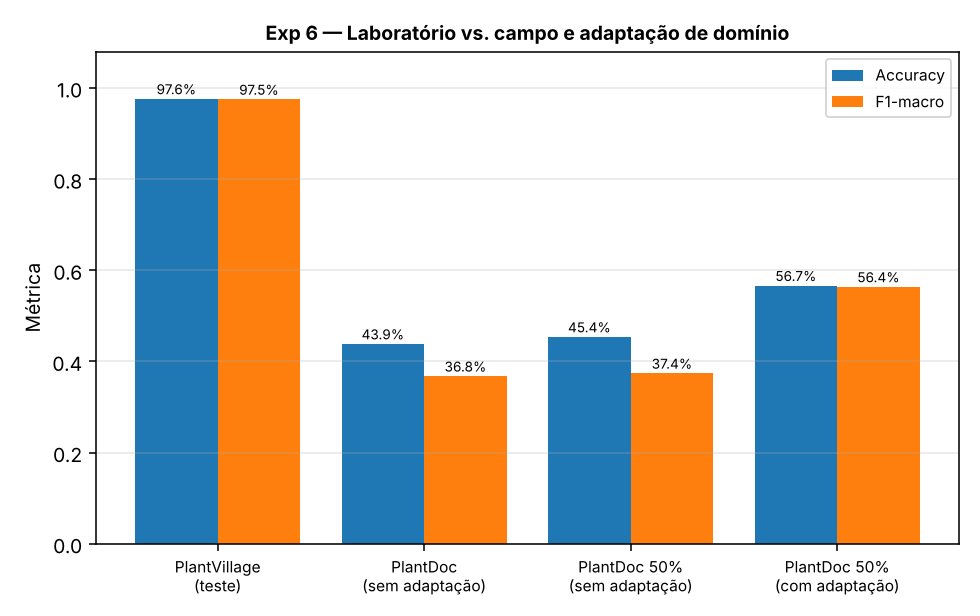

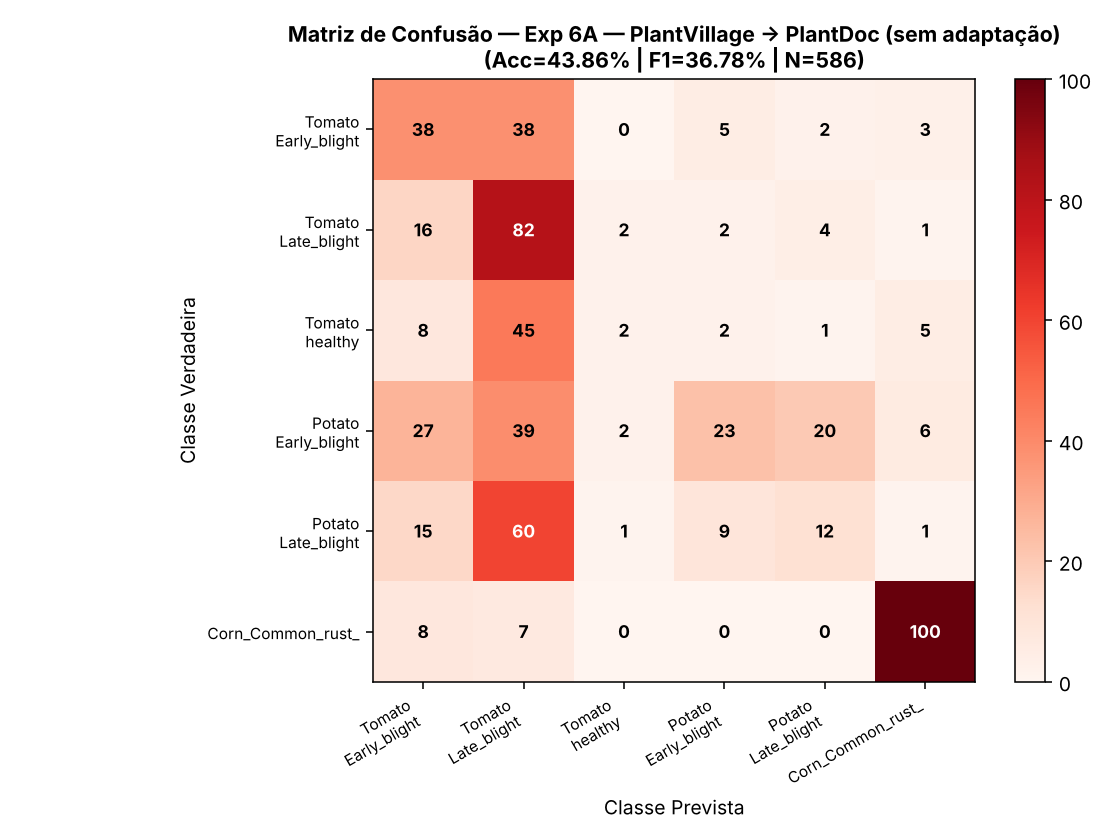

In [4]:
show('plots/exp6_generalization_comparison.png'); show('confusion_matrices/exp6_generalization_plantdoc_cm.png')